# EDA: семантика событий HDFS (мешок слов и TF-IDF)

Часть разведочного анализа к чекпойнту 2. Ответственный: Артем Погосян.
Распределение в команде: Аркадий отвечает за шаблоны, Степан за кластеры и временные ряды,
Табриз за общий EDA, Артем за семантику.

По уточнению куратора семантика здесь означает представление сессий через
**мешок слов** (bag of words, вектор счетчиков слов без учета порядка) и
**TF-IDF** (term frequency, inverse document frequency: счетчик слова,
умноженный на штраф за то, что слово встречается почти везде).

**Вопросы раздела**

1. Из каких слов состоят события HDFS и какие слова отличают аномальные сессии от нормальных.
2. Работает ли простое правило «в сессии есть тревожное слово, значит, аномалия».
3. Что меняет взвешивание TF-IDF по сравнению с сырыми счетчиками.
4. Насколько нормальные и аномальные сессии разделимы в пространстве слов и где предел такого представления.

**Данные.** HDFS_v1 из loghub, готовая разметка: 29 шаблонов событий (E1…E29),
матрица числа вхождений шаблонов в каждую сессию (сессия = все строки лога
одного блока `blk_…`) и метка сессии. Шаблоны взяты из набора как есть;
когда будут свои шаблоны Аркадия, тетрадь перезапускается на них.

Архив `HDFS_v1.zip` берется с Zenodo (https://zenodo.org/records/8196385) и распаковывается
в `data/loghub/HDFS_v1`, тетрадь запускается из корня репозитория. Нужны pandas, scikit-learn,
scipy, matplotlib и seaborn; sentence-transformers нужен только для дополнения в конце.

In [1]:
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import sparse
from sklearn.decomposition import TruncatedSVD
from sklearn.feature_extraction.text import CountVectorizer, TfidfTransformer, TfidfVectorizer
from sklearn.metrics import roc_auc_score
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.preprocessing import normalize

pd.set_option("display.max_colwidth", 120)
sns.set_theme(style="whitegrid", context="notebook")
RNG = np.random.default_rng(42)

DATA = Path("data/loghub/HDFS_v1/preprocessed")
EVENTS = [f"E{i}" for i in range(1, 30)]

## 1. Данные

Матрица `Event_occurrence_matrix.csv`: строка соответствует сессии (блоку), в столбцах E1…E29
число вхождений события в сессию. Метка `Fail` означает аномалию, `Type` содержит
код типа аномалии из исходной разметки (расшифровки кодов в наборе нет).

In [2]:
occ = pd.read_csv(DATA / "Event_occurrence_matrix.csv")
tpl = pd.read_csv(DATA / "HDFS.log_templates.csv")

y = (occ["Label"] == "Fail").astype(int).to_numpy()
X_ev = occ[EVENTS].to_numpy(dtype=np.int32)

print(f"сессий: {len(occ):,}".replace(",", " "))
print(f"аномалий: {y.sum():,} ({y.mean():.2%})".replace(",", " "))
print(f"шаблонов событий: {len(tpl)}")
tpl

сессий: 575 061
аномалий: 16 838 (2.93%)
шаблонов событий: 29


,EventId,EventTemplate
0,E1,[*]Adding an already existing block[*]
1,E2,[*]Verification succeeded for[*]
2,E3,[*]Served block[*]to[*]
3,E4,[*]Got exception while serving[*]to[*]
4,E5,[*]Receiving block[*]src:[*]dest:[*]
5,E6,[*]Received block[*]src:[*]dest:[*]of size[*]
6,E7,[*]writeBlock[*]received exception[*]
7,E8,[*]PacketResponder[*]for block[*]Interrupted[*]
8,E9,[*]Received block[*]of size[*]from[*]
9,E10,[*]PacketResponder[*]Exception[*]


## 2. Из каких слов состоят события

Шаблон это текст строки лога, в котором изменяемые части (номер блока, адрес,
размер) заменены на `[*]`. Чтобы получить слова, убираем `[*]`, разбиваем
составные имена из кода (`addStoredBlock` → add stored block, `PacketResponder`
→ packet responder) и выкидываем служебные слова (to, for, of…).
Отрицание `not` оставляем: в шаблоне E28 «does not belong to any file» оно несет смысл.
Слова src и dest тоже оставляем: без них шаблоны E6 «Received block … src … dest … of size»
(прием блока от клиента) и E9 «Received block … of size … from» (штатное подтверждение)
сливаются в одинаковый мешок слов, хотя ведут себя по-разному.

In [3]:
STOP = {"to", "for", "of", "from", "the", "as", "it", "does", "any", "in", "an",
        "on", "but", "is", "a", "while", "trying", "got"}


def tokenize(text):
    text = text.replace("[*]", " ")
    text = re.sub(r"([a-z])([A-Z])", r"\1 \2", text)  # camelCase -> camel Case
    text = re.sub(r"([A-Z]+)([A-Z][a-z])", r"\1 \2", text)  # BLOCKInfo -> BLOCK Info
    words = re.findall(r"[a-z]+", text.lower())
    return [w for w in words if w not in STOP]


tpl["words"] = tpl["EventTemplate"].map(tokenize)
tpl[["EventId", "EventTemplate", "words"]]

,EventId,EventTemplate,words
0,E1,[*]Adding an already existing block[*],"[adding, already, existing, block]"
1,E2,[*]Verification succeeded for[*],"[verification, succeeded]"
2,E3,[*]Served block[*]to[*],"[served, block]"
3,E4,[*]Got exception while serving[*]to[*],"[exception, serving]"
4,E5,[*]Receiving block[*]src:[*]dest:[*],"[receiving, block, src, dest]"
5,E6,[*]Received block[*]src:[*]dest:[*]of size[*],"[received, block, src, dest, size]"
6,E7,[*]writeBlock[*]received exception[*],"[write, block, received, exception]"
7,E8,[*]PacketResponder[*]for block[*]Interrupted[*],"[packet, responder, block, interrupted]"
8,E9,[*]Received block[*]of size[*]from[*],"[received, block, size]"
9,E10,[*]PacketResponder[*]Exception[*],"[packet, responder, exception]"


In [4]:
cv = CountVectorizer(analyzer=tokenize)
W = cv.fit_transform(tpl["EventTemplate"])  # шаблон x слово
VOCAB = cv.get_feature_names_out()
print(f"словарь: {len(VOCAB)} слова")
print(", ".join(VOCAB))

словарь: 64 слова
add, added, adding, allocate, already, ask, belong, block, changing, delete, deleting, dest, empty, error, exception, existing, failed, file, found, info, interrupted, invalid, map, meta, mirror, monitor, name, needed, not, offset, out, packet, pending, receive, received, receiving, redundant, removing, reopen, replicate, replication, replications, request, responder, served, serving, set, size, src, starting, stored, succeeded, system, terminating, thread, timed, transfer, transmitted, unexpected, updated, verification, volume, write, writing


Словарь крошечный: несколько десятков слов на 29 шаблонов. Это отличает логи
от обычных текстов, где словарь исчисляется тысячами слов: язык логов
ограничен тем, что разработчик зашил в код.

## 3. Сессия как документ: мешок слов

Сессию считаем документом, склеенным из текстов ее событий. Тогда мешок слов
сессии равен сумме векторов слов ее событий с учетом числа вхождений:
`BoW = X_ev · W`, где `X_ev` содержит счетчики событий (сессия × шаблон),
`W` описывает состав шаблонов (шаблон × слово). Так не нужно склеивать 11 млн строк
текста, результат тот же.

In [5]:
BoW = (sparse.csr_matrix(X_ev) @ W).tocsr().astype(np.float64)  # сессия x слово
print("размер:", BoW.shape)

present = (BoW > 0)
df_norm = np.asarray(present[y == 0].mean(axis=0)).ravel()  # доля нормальных сессий со словом
df_anom = np.asarray(present[y == 1].mean(axis=0)).ravel()  # доля аномальных сессий со словом
eps = 1e-4
words = pd.DataFrame({
    "слово": VOCAB,
    "доля в норме": df_norm,
    "доля в аномалиях": df_anom,
    "lift": (df_anom + eps) / (df_norm + eps),
}).sort_values("lift", ascending=False)
words.style.format({"доля в норме": "{:.2%}", "доля в аномалиях": "{:.2%}", "lift": "{:.1f}"})

размер: (575061, 64)


,слово,доля в норме,доля в аномалиях,lift
62,write,0.00%,19.62%,1962.6
42,request,0.00%,13.17%,1038.6
28,not,0.04%,37.86%,737.1
13,error,0.04%,30.44%,618.6
18,found,0.04%,30.44%,618.6
19,info,0.04%,30.44%,618.6
58,unexpected,0.04%,30.44%,618.6
61,volume,0.04%,30.44%,618.6
6,belong,0.00%,7.43%,612.3
36,redundant,0.00%,5.77%,548.2


`lift` (подъем) показывает, во сколько раз чаще слово встречается в аномальных сессиях,
чем в нормальных. Больше 1: слово тянет к аномалии, меньше 1: к норме.

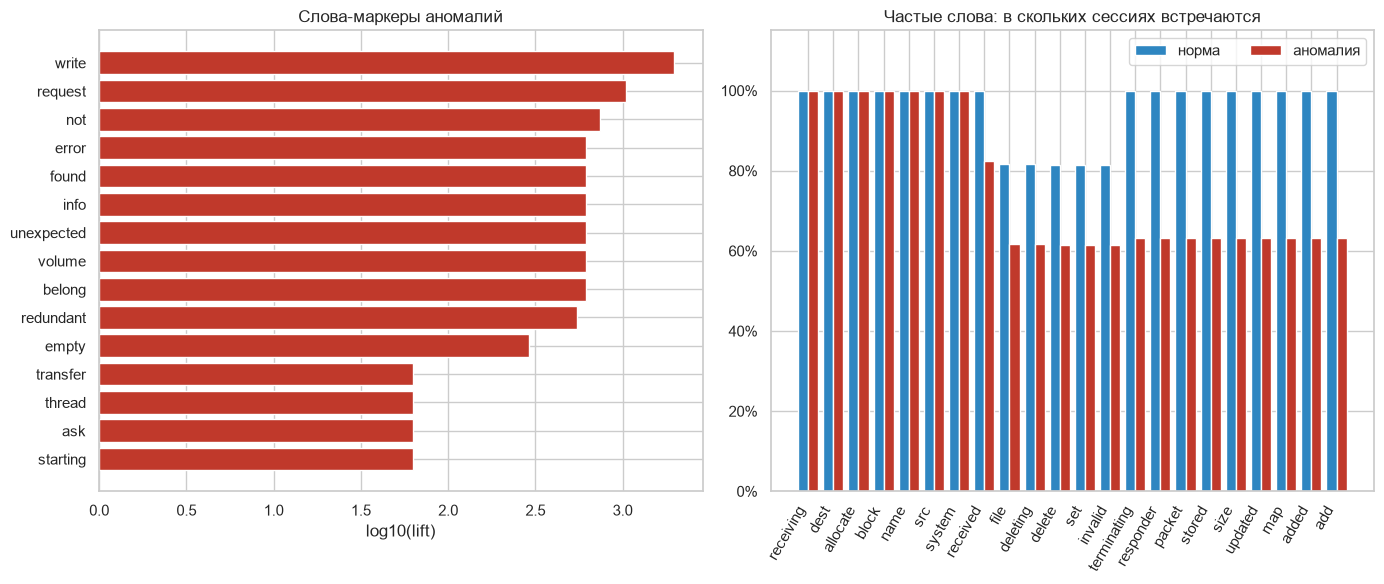

In [6]:
top = words.head(15).iloc[::-1]
low = words.tail(8).iloc[::-1]

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
axes[0].barh(top["слово"], np.log10(top["lift"]), color="#c0392b")
axes[0].set_title("Слова-маркеры аномалий")
axes[0].set_xlabel("log10(lift)")
both = words[(words["доля в норме"] > 0.5)]
x = np.arange(len(both))
axes[1].bar(x - 0.2, both["доля в норме"], 0.4, label="норма", color="#2e86c1")
axes[1].bar(x + 0.2, both["доля в аномалиях"], 0.4, label="аномалия", color="#c0392b")
axes[1].set_xticks(x, both["слово"], rotation=60, ha="right")
axes[1].set_title("Частые слова: в скольких сессиях встречаются")
axes[1].yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
axes[1].set_ylim(0, 1.15)
axes[1].legend(ncol=2, loc="upper right")
plt.tight_layout()
plt.show()

Два вида сигнала видны сразу.

* **Присутствие.** Есть слова, которых в норме нет совсем: interrupted,
  timed, mirror, redundant, offset… Их появление почти гарантирует аномалию.
* **Отсутствие.** Слова штатного завершения записи блока (terminating,
  stored, updated) есть в каждой нормальной сессии, а в аномальных
  пропадают примерно в трети случаев. Аномалия видна не только по «плохому»
  слову, но и по тому, что «хорошее» слово так и не появилось.

## 4. Правило «есть тревожное слово, значит, аномалия»

Самый очевидный подход без машинного обучения: искать в логе слова вроде
exception или failed. Проверим, сколько аномалий он ловит (recall, полнота)
и какая доля тревог настоящая (precision, точность).

In [7]:
ALARM = ["exception", "error", "failed", "interrupted", "timed", "unexpected"]


def rule_quality(flag):
    tp = int((flag & (y == 1)).sum())
    fp = int((flag & (y == 0)).sum())
    return {"тревог": int(flag.sum()), "верных": tp, "ложных": fp,
            "precision": tp / max(flag.sum(), 1), "recall": tp / y.sum()}


rows = []
for w in ALARM:
    j = list(VOCAB).index(w) if w in VOCAB else None
    if j is None:
        continue
    flag = BoW[:, j].toarray().ravel() > 0
    rows.append({"правило": f"есть «{w}»", **rule_quality(flag)})
alarm_idx = [list(VOCAB).index(w) for w in ALARM if w in VOCAB]
any_alarm = np.asarray((BoW[:, alarm_idx] > 0).sum(axis=1)).ravel() > 0
rows.append({"правило": "любое тревожное слово", **rule_quality(any_alarm)})
rules = pd.DataFrame(rows)
rules.style.format({"precision": "{:.1%}", "recall": "{:.1%}"})

,правило,тревог,верных,ложных,precision,recall
0,есть «exception»,132593,6476,126117,4.9%,38.5%
1,есть «error»,5345,5126,219,95.9%,30.4%
2,есть «failed»,9,9,0,100.0%,0.1%
3,есть «interrupted»,46,46,0,100.0%,0.3%
4,есть «timed»,46,46,0,100.0%,0.3%
5,есть «unexpected»,5345,5126,219,95.9%,30.4%
6,любое тревожное слово,136761,10641,126120,7.8%,63.2%


In [8]:
# откуда ложные тревоги: какие шаблоны с тревожными словами встречаются в норме
alarm_tpl = tpl[tpl["words"].map(lambda ws: any(w in ALARM for w in ws))].copy()
alarm_tpl["сессий в норме"] = [(X_ev[y == 0, EVENTS.index(e)] > 0).sum() for e in alarm_tpl["EventId"]]
alarm_tpl["сессий в аномалиях"] = [(X_ev[y == 1, EVENTS.index(e)] > 0).sum() for e in alarm_tpl["EventId"]]
alarm_tpl[["EventId", "EventTemplate", "сессий в норме", "сессий в аномалиях"]]

,EventId,EventTemplate,сессий в норме,сессий в аномалиях
3,E4,[*]Got exception while serving[*]to[*],126117,3178
6,E7,[*]writeBlock[*]received exception[*],0,3303
7,E8,[*]PacketResponder[*]for block[*]Interrupted[*],0,46
9,E10,[*]PacketResponder[*]Exception[*],0,67
11,E12,[*]:Exception writing block[*]to mirror[*],0,26
13,E14,[*]Exception in receiveBlock for block[*],0,63
16,E17,[*]:Failed to transfer[*]to[*]got[*],0,9
19,E20,[*]Unexpected error trying to delete block[*]BlockInfo not found in volumeMap[*],219,5126
28,E29,[*]PendingReplicationMonitor timed out block[*],0,46


Почти все ложные тревоги дает один шаблон E4 «Got exception while serving
… to …»: это штатная ситуация, когда клиент оборвал чтение блока, и она
встречается в каждой пятой нормальной сессии. Слово exception само по себе
не означает сбой: смысл задает контекст, а не отдельное слово.

Посмотрим, сколько дает правило без E4 и что добавляет признак отсутствия
слов завершения.

In [9]:
e4 = X_ev[:, EVENTS.index("E4")] > 0
alarm_wo_e4 = np.zeros(len(y), dtype=bool)
for e in alarm_tpl["EventId"]:
    if e != "E4":
        alarm_wo_e4 |= X_ev[:, EVENTS.index(e)] > 0

done_idx = [list(VOCAB).index(w) for w in ["terminating", "stored"]]
no_finish = np.asarray((BoW[:, done_idx] > 0).sum(axis=1)).ravel() < len(done_idx)

cmp = pd.DataFrame([
    {"правило": "любое тревожное слово", **rule_quality(any_alarm)},
    {"правило": "тревожное слово, кроме шаблона E4", **rule_quality(alarm_wo_e4)},
    {"правило": "нет слов завершения (terminating, stored)", **rule_quality(no_finish)},
    {"правило": "тревожное слово без E4 ИЛИ нет завершения", **rule_quality(alarm_wo_e4 | no_finish)},
])
cmp.style.format({"precision": "{:.1%}", "recall": "{:.1%}"})

,правило,тревог,верных,ложных,precision,recall
0,любое тревожное слово,136761,10641,126120,7.8%,63.2%
1,"тревожное слово, кроме шаблона E4",8687,8468,219,97.5%,50.3%
2,"нет слов завершения (terminating, stored)",6207,6207,0,100.0%,36.9%
3,тревожное слово без E4 ИЛИ нет завершения,11637,11418,219,98.1%,67.8%


In [10]:
silent = (y == 1) & ~alarm_wo_e4 & ~no_finish
print(f"аномалий без тревожных слов и с нормальным завершением: {silent.sum():,} "
      f"({silent.sum() / y.sum():.1%} всех аномалий)".replace(",", " "))

аномалий без тревожных слов и с нормальным завершением: 5 420 (32.2% всех аномалий)


Оговорка: правило без E4 и признак завершения подобраны с оглядкой на
метки, поэтому их цифры дают верхнюю границу для правил, а не честную оценку.
Честное сравнение будет в чекпойнте 3 на отложенной выборке.

## 5. TF-IDF: зачем взвешивать слова

В сыром мешке слов доминируют слова массовых событий. Например, served из
E3 «Served block … to …» в одной сессии может встретиться сотни раз, и
вектор сессии фактически превращается в счетчик чтений блока. TF-IDF
исправляет это двумя множителями:

* **TF**: сколько раз слово встретилось в сессии;
* **IDF** = ln((1 + N) / (1 + df)) + 1, где N это число сессий, df показывает, в скольких
  сессиях слово есть. Слово из каждой сессии получает IDF ≈ 1, редкое получает большой вес.

Затем вектор нормируется на длину 1, чтобы длинные и короткие сессии были сравнимы.
Вариант **sublinear TF** заменяет счетчик на 1 + ln(TF): слово, встреченное
200 раз, весит не в 200, а примерно в 6 раз больше слова, встреченного один раз.

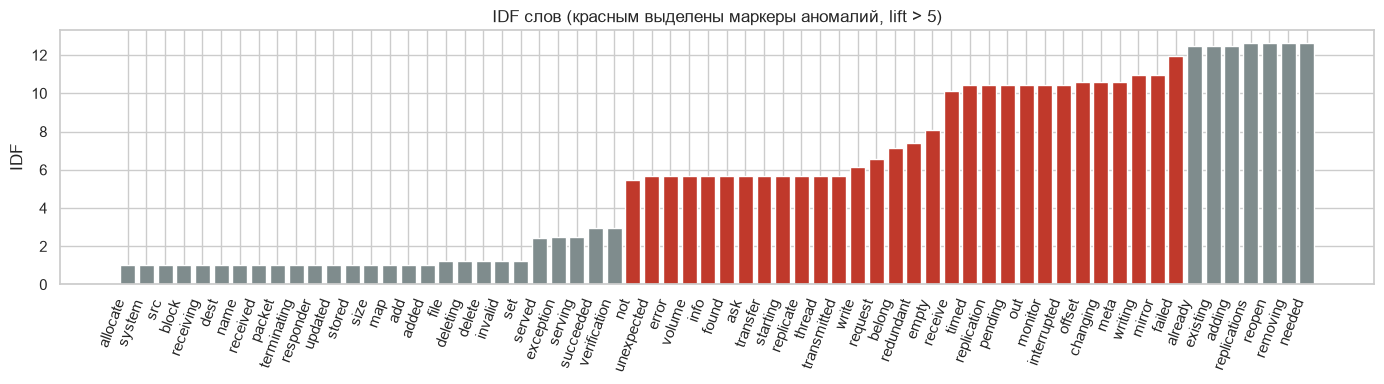

In [11]:
tfidf_w = TfidfTransformer()  # smooth_idf=True, norm="l2"
T = tfidf_w.fit_transform(BoW)
T_log = TfidfTransformer(sublinear_tf=True).fit_transform(BoW)
idf = pd.Series(tfidf_w.idf_, index=VOCAB).sort_values()

fig, ax = plt.subplots(figsize=(14, 4))
colors = ["#c0392b" if words.set_index("слово").loc[w, "lift"] > 5 else "#7f8c8d" for w in idf.index]
ax.bar(idf.index, idf.values, color=colors)
ax.set_title("IDF слов (красным выделены маркеры аномалий, lift > 5)")
ax.set_ylabel("IDF")
plt.xticks(rotation=70, ha="right")
plt.tight_layout()
plt.show()

In [12]:
# одна и та же сессия глазами мешка слов и TF-IDF
i = int(np.flatnonzero((y == 1) & (X_ev[:, EVENTS.index("E3")] > 20))[0])
bow_i = pd.Series(BoW[i].toarray().ravel(), index=VOCAB)
tf_i = pd.Series(T[i].toarray().ravel(), index=VOCAB)
tl_i = pd.Series(T_log[i].toarray().ravel(), index=VOCAB)
side = pd.DataFrame({
    "мешок слов: слово": bow_i.sort_values(ascending=False).head(8).index,
    "счетчик": bow_i.sort_values(ascending=False).head(8).values.astype(int),
    "TF-IDF: слово": tf_i.sort_values(ascending=False).head(8).index,
    "вес": tf_i.sort_values(ascending=False).head(8).values.round(3),
    "sublinear TF-IDF: слово": tl_i.sort_values(ascending=False).head(8).index,
    "вес ": tl_i.sort_values(ascending=False).head(8).values.round(3),
})
print(occ.loc[i, "BlockId"], "аномалия, тип", int(occ.loc[i, "Type"]))
side

blk_-3544583377289625738 аномалия, тип 21


,мешок слов: слово,счетчик,TF-IDF: слово,вес,sublinear TF-IDF: слово,вес
0,block,231,served,0.905,served,0.633
1,served,203,block,0.424,block,0.266
2,system,7,name,0.013,unexpected,0.234
3,name,7,system,0.013,volume,0.234
4,added,6,added,0.011,error,0.234
5,size,6,size,0.011,info,0.234
6,delete,4,error,0.010,found,0.234
7,map,4,info,0.010,not,0.226


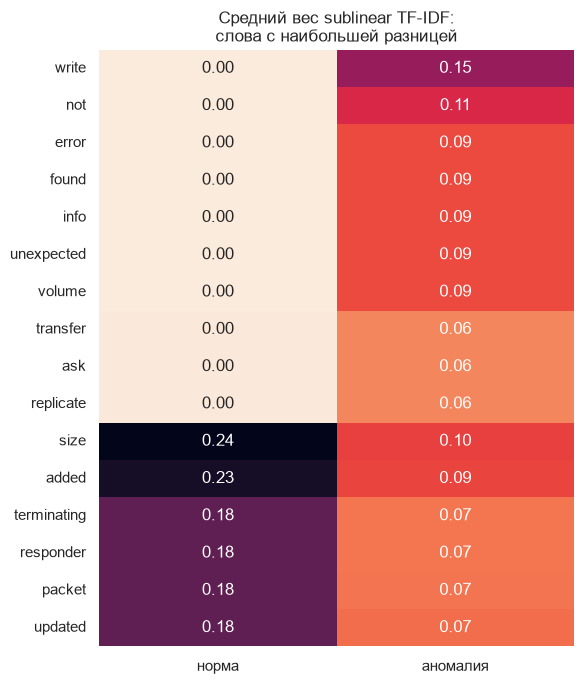

In [13]:
# средний профиль класса по sublinear TF-IDF (в обычном все забивает block): какие слова весомы в норме и в аномалии
prof = pd.DataFrame({
    "норма": np.asarray(T_log[y == 0].mean(axis=0)).ravel(),
    "аномалия": np.asarray(T_log[y == 1].mean(axis=0)).ravel(),
}, index=VOCAB)
prof["разница"] = prof["аномалия"] - prof["норма"]
show = pd.concat([prof.nlargest(10, "разница"), prof.nsmallest(6, "разница")])

fig, ax = plt.subplots(figsize=(6, 7))
sns.heatmap(show[["норма", "аномалия"]], annot=True, fmt=".2f", cmap="rocket_r", cbar=False, ax=ax)
ax.set_title("Средний вес sublinear TF-IDF:\nслова с наибольшей разницей")
plt.tight_layout()
plt.show()

## 6. TF-IDF на уровне событий

Тот же прием можно применить не к словам, а к номерам событий: сессия считается
документом, событие E1…E29 считается «словом». Так делают классические работы по логам
(loglizer, He et al., 2016). Слова и события дают разную картину, потому что
одно слово (block, received) входит в несколько шаблонов.

In [14]:
tfidf_e = TfidfTransformer()
T_ev = tfidf_e.fit_transform(sparse.csr_matrix(X_ev.astype(np.float64)))
idf_ev = pd.DataFrame({
    "IDF": tfidf_e.idf_,
    "доля сессий": (X_ev > 0).mean(axis=0),
    "шаблон": tpl.set_index("EventId").loc[EVENTS, "EventTemplate"].to_numpy(),
}, index=EVENTS).sort_values("IDF")
idf_ev.style.format({"IDF": "{:.2f}", "доля сессий": "{:.3%}"})

,IDF,доля сессий,шаблон
E22,1.00,100.000%,[*]BLOCK* NameSystem[*]allocateBlock:[*]
E5,1.00,100.000%,[*]Receiving block[*]src:[*]dest:[*]
E11,1.01,98.925%,[*]PacketResponder[*]for block[*]terminating[*]
E9,1.01,98.921%,[*]Received block[*]of size[*]from[*]
E26,1.01,98.921%,[*]BLOCK* NameSystem[*]addStoredBlock: blockMap updated:[*]is added to[*]size[*]
E21,1.21,81.147%,[*]Deleting block[*]file[*]
E23,1.21,80.864%,[*]BLOCK* NameSystem[*]delete:[*]is added to invalidSet of[*]
E3,2.43,23.899%,[*]Served block[*]to[*]
E4,2.49,22.484%,[*]Got exception while serving[*]to[*]
E2,2.94,14.382%,[*]Verification succeeded for[*]


## 7. Разделимость в пространстве слов

Проецируем векторы сессий на плоскость методом TruncatedSVD (аналог метода
главных компонент для разреженных матриц) и смотрим, ложатся ли аномалии
отдельно. Берем выборку: 20 000 нормальных и 5 000 аномальных сессий.

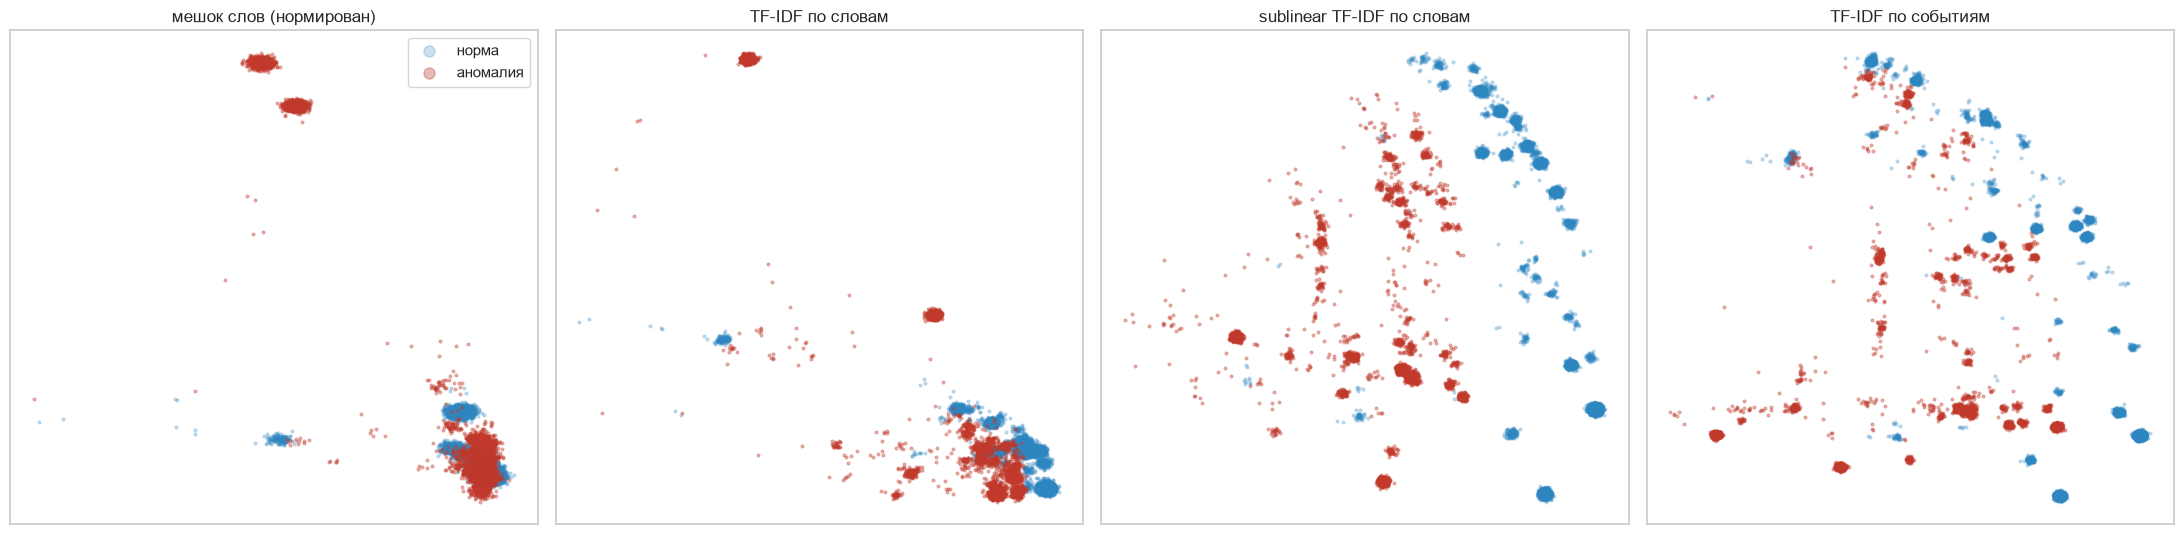

In [15]:
idx = np.concatenate([
    RNG.choice(np.flatnonzero(y == 0), 20_000, replace=False),
    RNG.choice(np.flatnonzero(y == 1), 5_000, replace=False),
])
reps = {
    "мешок слов (нормирован)": normalize(BoW),
    "TF-IDF по словам": T,
    "sublinear TF-IDF по словам": T_log,
    "TF-IDF по событиям": T_ev,
}
fig, axes = plt.subplots(1, 4, figsize=(22, 5.5))
for ax, (name, M) in zip(axes, reps.items()):
    Z = TruncatedSVD(n_components=2, random_state=42).fit_transform(M[idx])
    jitter = RNG.normal(0, 0.004, Z.shape)
    for lab, col, a in [(0, "#2e86c1", 0.25), (1, "#c0392b", 0.35)]:
        m = y[idx] == lab
        ax.scatter(*(Z[m] + jitter[m]).T, s=4, alpha=a, c=col, label=["норма", "аномалия"][lab])
    ax.set_title(name)
    ax.set_xticks([]); ax.set_yticks([])
axes[0].legend(markerscale=4)
plt.tight_layout()
plt.show()

Картинка на плоскости теряет много информации, поэтому дополним ее числом.
Простейшая мера «непохожести на норму» без обучения: косинусное расстояние
от сессии до среднего вектора нормальных сессий. Чем лучше представление,
тем выше ROC AUC (вероятность, что случайная аномалия окажется дальше от
нормы, чем случайная нормальная сессия; 0.5 означает угадывание, 1 идеал).
Это ориентир для разведки, а не модель: центр нормы считается по всем
нормальным сессиям, без разбиения на обучение и проверку.

In [16]:
res = []
for name, M in reps.items():
    centre = normalize(np.asarray(M[y == 0].mean(axis=0)))
    dist = 1 - (normalize(M) @ centre.T).ravel()
    thr = np.quantile(dist[y == 0], 0.99)  # порог: 1% ложных тревог на норме
    res.append({"представление": name, "ROC AUC": roc_auc_score(y, dist),
                "recall при 1% ложных тревог": (dist[y == 1] > thr).mean()})
pd.DataFrame(res).style.format({"ROC AUC": "{:.3f}", "recall при 1% ложных тревог": "{:.1%}"})

,представление,ROC AUC,recall при 1% ложных тревог
0,мешок слов (нормирован),0.816,38.3%
1,TF-IDF по словам,0.965,42.5%
2,sublinear TF-IDF по словам,0.997,96.1%
3,TF-IDF по событиям,0.942,47.8%


## 8. Предел мешка слов

Мешок слов не видит порядок событий. Если аномальная сессия по набору слов
(с учетом счетчиков) совпадает с какой-то нормальной, никакая модель поверх
мешка слов их не различит.

In [17]:
B = BoW.toarray().astype(np.int32)
keys = pd.util.hash_pandas_object(pd.DataFrame(B), index=False).to_numpy()
normal_keys = set(keys[y == 0])
twin = np.array([k in normal_keys for k in keys[y == 1]])
print(f"различных векторов мешка слов: {len(set(keys)):,}".replace(",", " "))
print(f"  из них у нормальных сессий: {len(normal_keys):,}".replace(",", " "))
print(f"аномалий с точным двойником среди нормальных: {twin.sum():,} ({twin.mean():.1%})".replace(",", " "))

# то же на уровне событий: совпадает ли картина
keys_ev = pd.util.hash_pandas_object(pd.DataFrame(X_ev), index=False).to_numpy()
twin_ev = np.isin(keys_ev[y == 1], keys_ev[y == 0])
print(f"то же по счетчикам событий: {twin_ev.sum():,} ({twin_ev.mean():.1%})".replace(",", " "))

различных векторов мешка слов: 589
  из них у нормальных сессий: 212
аномалий с точным двойником среди нормальных: 319 (1.9%)
то же по счетчикам событий: 319 (1.9%)


## 9. Слова и типы аномалий

В разметке у аномалий есть код типа (`Type`). Расшифровки кодов в наборе нет,
но по словам можно понять, что за сбой стоит за каждым крупным типом.

In [18]:
types = occ.loc[y == 1, "Type"].value_counts()
rows = []
for t, n in types.head(8).items():
    m = (occ["Type"] == t).to_numpy()
    d = np.asarray(present[m].mean(axis=0)).ravel()
    lift_t = (d + eps) / (df_norm + eps)
    top_w = [VOCAB[j] for j in np.argsort(-lift_t)[:5] if lift_t[j] > 2]
    gone = [VOCAB[j] for j in np.argsort(lift_t)[:3] if lift_t[j] < 0.5]
    rows.append({"тип": int(t), "сессий": n, "доля аномалий": n / y.sum(),
                 "характерные слова": ", ".join(top_w) or "нет",
                 "пропадают": ", ".join(gone) or "нет"})
pd.DataFrame(rows).style.format({"доля аномалий": "{:.1%}"})

,тип,сессий,доля аномалий,характерные слова,пропадают
0,5,4167,24.7%,"error, volume, info, unexpected, found","served, serving, exception"
1,31,3225,19.2%,"write, exception","add, updated, terminating"
2,3,2950,17.5%,нет,"add, updated, terminating"
3,0,2809,16.7%,"transmitted, starting, replicate, ask, thread",нет
4,4,1240,7.4%,"belong, request, not, removing, needed",нет
5,1,953,5.7%,"redundant, request, not, volume, unexpected",нет
6,21,724,4.3%,"info, volume, error, unexpected, found",нет
7,7,476,2.8%,"empty, transmitted, starting, transfer, thread","serving, exception, not"


## 10. Смысловая близость шаблонов

Последний взгляд на сами шаблоны: какие события говорят об одном и том же.
TF-IDF по текстам 29 шаблонов, косинусное сходство и иерархическая
кластеризация (дерево слева и сверху объединяет похожие шаблоны).
Эти группы служат кандидатами на укрупнение событий для моделей чекпойнта 3
и подсказкой для части Аркадия по шаблонам.

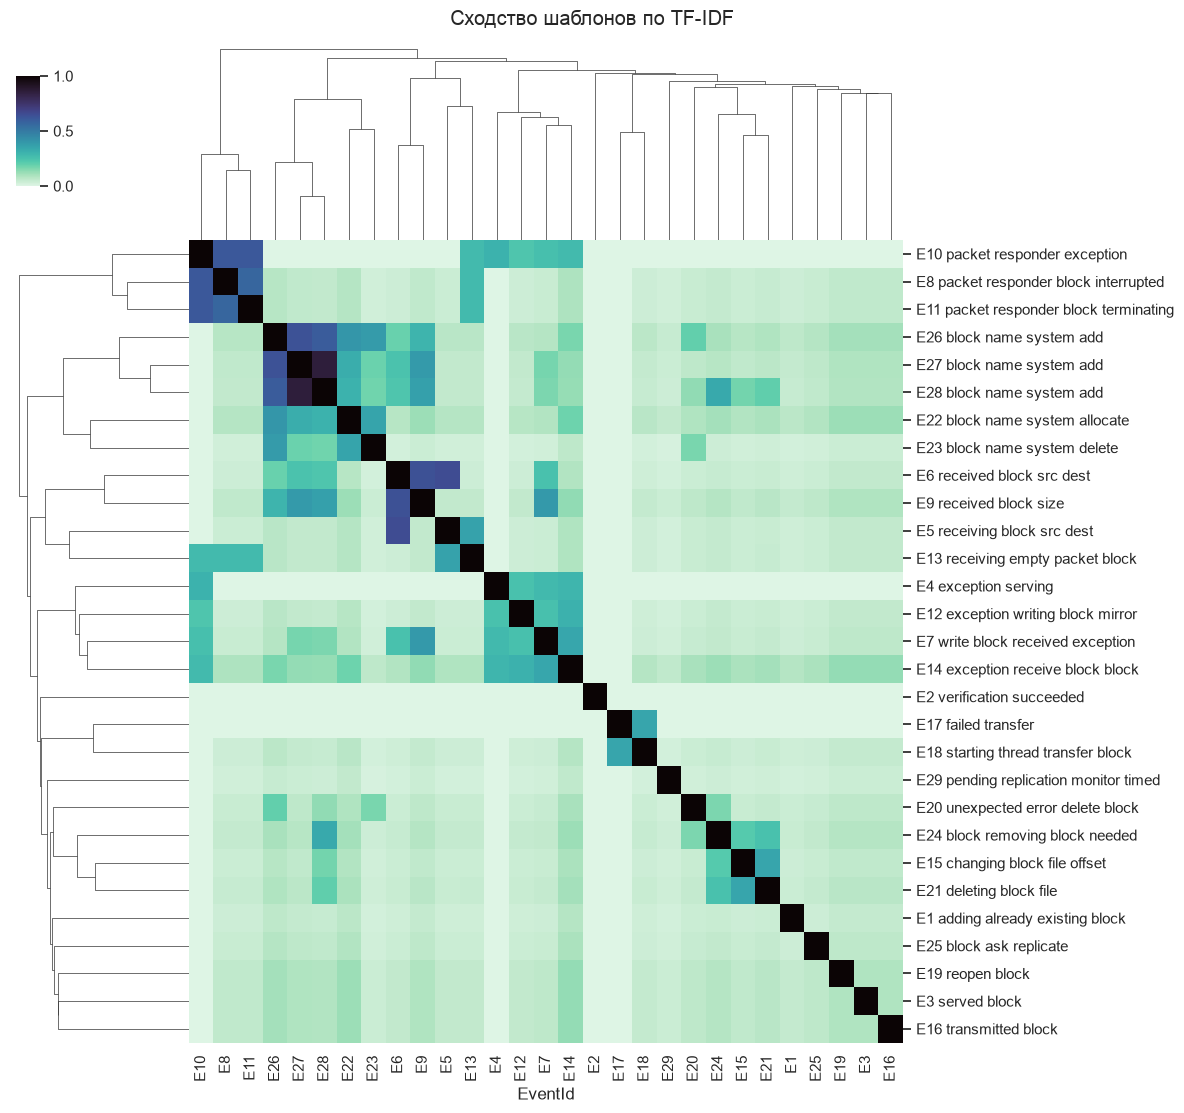

In [19]:
tv = TfidfVectorizer(analyzer=tokenize)
S = cosine_similarity(tv.fit_transform(tpl["EventTemplate"]))
labels = [f"{e} " + " ".join(ws[:4]) for e, ws in zip(tpl["EventId"], tpl["words"])]
g = sns.clustermap(pd.DataFrame(S, index=labels, columns=tpl["EventId"]),
                   cmap="mako_r", figsize=(12, 11), method="average",
                   cbar_pos=(0.02, 0.85, 0.02, 0.1))
g.fig.suptitle("Сходство шаблонов по TF-IDF", y=1.01)
plt.show()

### Дополнение: эмбеддинги вместо TF-IDF

Для сравнения те же шаблоны через предобученную языковую модель
(`all-MiniLM-L6-v2`, sentence-transformers). Она знает, что failed и
exception близки по смыслу, хотя это разные слова, а TF-IDF этого не видит.
В основной анализ не входит, это задел на чекпойнт 6 (нейросети).

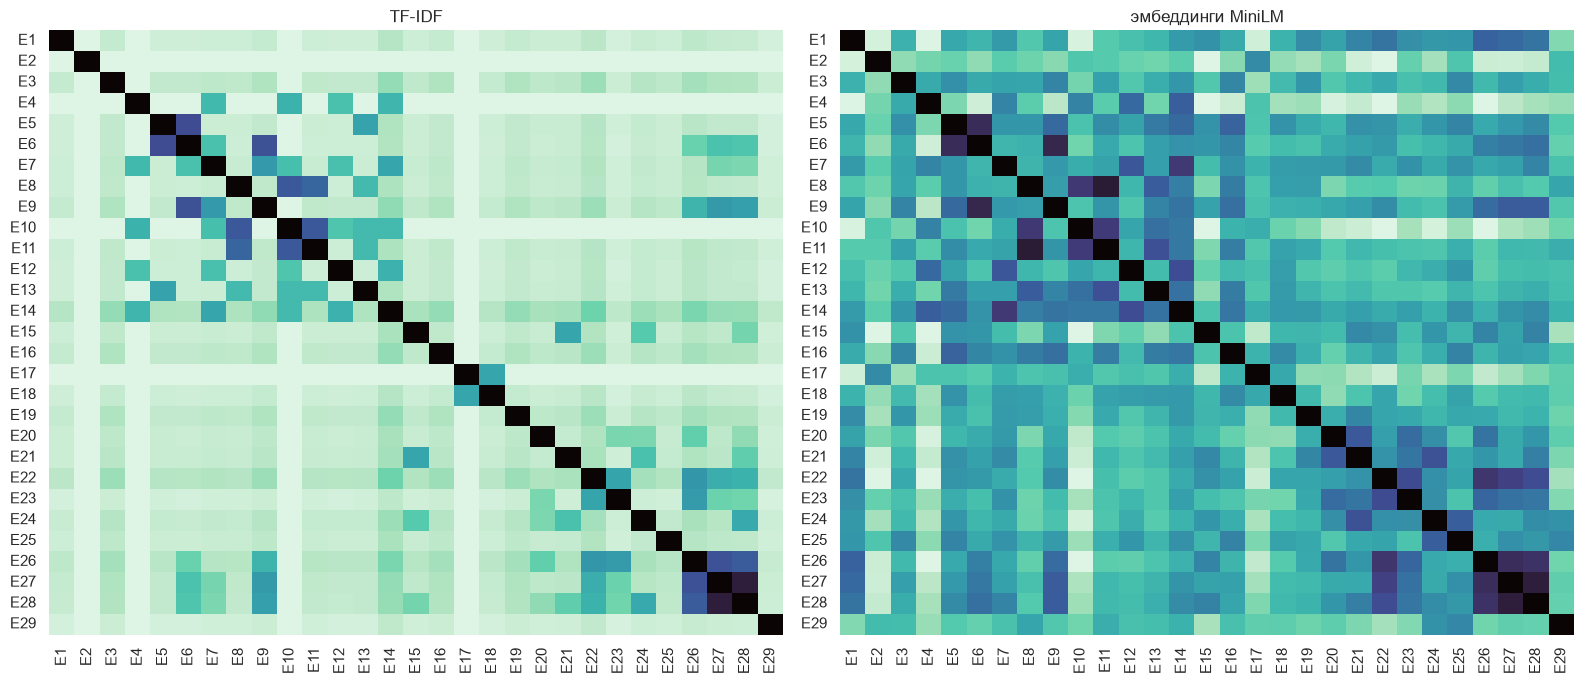

Пары, которые модель считает близкими, а TF-IDF нет:


,a,b,TF-IDF,эмбеддинги,разница
361,E20,E21,0.05,0.61,0.56
391,E24,E25,0.06,0.59,0.54
116,E5,E16,0.06,0.58,0.52
24,E1,E26,0.06,0.58,0.52
25,E1,E27,0.05,0.56,0.51
109,E5,E9,0.06,0.56,0.50


In [20]:
import logging, os, warnings
os.environ["TQDM_DISABLE"] = "1"
os.environ["TRANSFORMERS_VERBOSITY"] = "error"
warnings.filterwarnings("ignore")
logging.getLogger("torch").setLevel(logging.ERROR)
try:
    from sentence_transformers import SentenceTransformer

    texts = [" ".join(ws) for ws in tpl["words"]]
    emb = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2").encode(texts, normalize_embeddings=True)
    S_emb = emb @ emb.T
    fig, axes = plt.subplots(1, 2, figsize=(16, 7))
    for ax, M, name in [(axes[0], S, "TF-IDF"), (axes[1], S_emb, "эмбеддинги MiniLM")]:
        sns.heatmap(M, xticklabels=tpl["EventId"], yticklabels=tpl["EventId"], cmap="mako_r",
                    vmin=0, vmax=1, ax=ax, cbar=False)
        ax.set_title(name)
    plt.tight_layout()
    plt.show()

    iu = np.triu_indices(len(tpl), 1)
    pairs = pd.DataFrame({"a": tpl["EventId"].to_numpy()[iu[0]], "b": tpl["EventId"].to_numpy()[iu[1]],
                          "TF-IDF": S[iu], "эмбеддинги": S_emb[iu]})
    pairs["разница"] = pairs["эмбеддинги"] - pairs["TF-IDF"]
    print("Пары, которые модель считает близкими, а TF-IDF нет:")
    display(pairs.nlargest(6, "разница").round(2))
except Exception as e:  # нет пакета или нет доступа к модели: основной анализ от этого не зависит
    print(f"дополнение пропущено: {type(e).__name__}")

## Выводы

1. **Язык логов беден.** 29 шаблонов HDFS дают словарь из 64 слов. Поэтому
   мешок слов здесь компактен (64 признака на сессию) и полностью интерпретируем:
   каждый признак можно прочитать глазами.

2. **Аномалию выдают два вида слов.**
   * *Присутствие:* write (19,6% аномалий, в норме не встречается), not
     (37,9% против 0,04%), error и unexpected (30,4% против 0,04%), redundant, empty.
   * *Отсутствие:* слова штатного завершения записи блока (terminating, stored,
     updated) есть в каждой нормальной сессии и пропадают в 36,9% аномалий.

3. **Поиск по тревожному слову не работает «в лоб».** Слово exception дает
   precision 4,9%: 126 117 ложных тревог почти целиком от шаблона E4 «Got
   exception while serving», штатного обрыва чтения клиентом. Любое тревожное
   слово ловит 63,2% аномалий при точности 7,8%. Если исключить E4 и добавить
   признак отсутствия завершения, получается precision 98,1% и recall 67,8%,
   но это верхняя граница: правило подобрано с оглядкой на метки.
   32,2% аномалий «молчат»: в них нет тревожных слов и завершение на месте.

4. **TF-IDF нужен, и именно с логарифмом счетчика.** В сыром мешке слов и в
   обычном TF-IDF вектор сессии забивают массовые слова served и block (сотни
   чтений блока). Sublinear TF (1 + ln TF) поднимает наверх смысловые слова.
   Простая мера «расстояние до средней нормальной сессии» без обучения:

   | представление | ROC AUC | recall при 1% ложных тревог |
   | --- | --- | --- |
   | мешок слов | 0,816 | 38,3% |
   | TF-IDF по словам | 0,965 | 42,5% |
   | **sublinear TF-IDF по словам** | **0,997** | **96,1%** |
   | TF-IDF по событиям | 0,942 | 47,8% |

   Цифры предварительные: центр нормы считался по всем нормальным сессиям.
   Честная проверка на временном разбиении будет в чекпойнте 3.

5. **Предел мешка слов около 98% recall.** Во всем наборе всего 589 различных
   векторов слов, из них 212 у нормальных сессий. 319 аномалий (1,9%) по
   набору слов в точности совпадают с нормальными сессиями: их не отличит ни
   одна модель на мешке слов, нужны порядок событий и время (часть Степана).

6. **Слова объясняют типы аномалий.** Крупнейший тип 5 (24,7% аномалий) это
   ошибка удаления блока (unexpected error … not found in volumeMap); тип 31
   (19,2%) это исключение при записи без штатного завершения; тип 3 (17,5%)
   не имеет своих слов и виден только по пропаже завершения; тип 0 (16,7%) это
   внеплановая репликация блока (ask, replicate, transfer).

7. **Гранулярность шаблонов важна.** Если выбросить слова src и dest, шаблоны
   E6 (прием блока от клиента, есть в 20,6% аномалий) и E9 (штатное
   подтверждение) сливаются в одно. Для части Аркадия: при своем разборе
   шаблонов такие пары нельзя склеивать.

**Что это дает проекту.** Для чекпойнта 3 предлагаем sublinear TF-IDF по
словам как базовое представление сессии для моделей без учителя (PCA,
Isolation Forest, кластеризация): оно дешевое, читаемое и уже без обучения
дает сильный ориентир. Порог выбирать под целевой recall, как просил куратор:
даже 1% ложных тревог означает около 5 600 нормальных сессий.